# Lab 08: Graphs, latent variables, and what the survey didn't keep

**ASTR 457, Fall 2026, posted Thu Oct 29, due Wed Nov 4 by noon (fork → PR, as always)**

This week we wrote graphs as `PyMC` code, and put a detector into the likelihood. You're going to do both, on your own midterm supernovae, on a survey that rejects everything below a threshold, and on one real Type Ia supernova observed in six bands.

Put your notebook in `submissions/<your netid>/lab08.ipynb` - the data paths below are relative to that folder. It has to run top to bottom from a fresh kernel ("Restart & Run All").

Part 1 is 35%, Part 2 30%, Part 3 25%, and the AI-use appendix and verification plan 10%. Quote every number with its unit (if it has one), an error bar, and a sensible number of digits.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.optimize import minimize
import pymc as pm
import pytensor.tensor as pt
import arviz as az

NETID = 'saumyap2'   # <-- set this
LAB = '../../labs/08/data/'                              # from submissions/<your netid>/
MIDTERM = f'../../labs/midterm/data/{NETID}/'

## Part 1: Your midterm, as a graph (35%)

On the midterm you fit the Tripp relation to your 250 supernovae (`p2_pantheon_sne.csv` in your midterm data folder):

$$m_B = M + \mu(z) - \alpha\,x_1 + \beta\,c + \gamma\,\Theta(\log M_\star - 10).$$

In the posted solution's 2e simulation, the 68% interval on $\beta$ contained the true $\beta$ in only **6%** of 200 fake datasets! The other four parameters covered the truth 62-66% of the time. The solution blamed attenuation. You're going to draw the graph that shows where it comes from, build the model that removes it, and check that it does.

1. Draw the probabilistic graphical model of your midterm fit (your 2b likelihood), using the same key as Day 18 - parameters you fit as blue circles, latent (unobserved) values as white circles, data as grey circles, fixed quantities as dots, and a plate over supernovae. Draw it by hand (a photo is fine) or with any drawing tool, and put the image in your notebook. Then draw the graph of how the data were actually made. Each supernova has a *true* stretch $x_{1,i}$ and a *true* color $c_i$, drawn from a population (a mean and a width for each), and the catalog's $\hat m_{B,i}$, $\hat x_{1,i}$, $\hat c_i$ are noisy measurements of the true values, with that supernova's $3\times3$ covariance $C_i$. Which arrows does the midterm's graph lack, and which circle did it shade grey that should be white?
2. Fit the second graph in `PyMC`, with latent `x1_true` and `c_true` (one per supernova, `shape=N`), a mean and a width for each population, and the three observed quantities together in a `pm.MvNormal` with each $C_i$. Add $\sigma_{\rm int}^2$ and the peculiar-velocity variance to the $m_B$ term only. Handle the contaminants as you did on the midterm, and explain how. Pick centered or non-centered by Day 19's rule (compare the measurement errors with the population widths), and justify your choice. Report the largest $\hat R$, the smallest bulk effective sample size (the latent values included) and the number of divergences, then $\alpha$, $\beta$, $\gamma$ and $\sigma_{\rm int}$ as medians with 68% intervals, in a table next to your midterm values.
3. Rerun the solution's 2e simulation at your own stretches, colors and covariances, with at least 20 fake datasets and true $\beta = 2.9$ (the other true values are in the solution, which uses your catalog $x_1$ and $c$ as the true ones). Fit each with your midterm model and with the latent model, and report the mean $\hat\beta$ for each model with its standard error (the scatter over datasets divided by $\sqrt{N_{\rm sim}}$). Then explain, in a few sentences, why using the measured $x_1$ and $c$ as the regressors, with their errors only in the variance (as the midterm did), biases $\beta$ toward zero, why the latent model doesn't, and why $\beta$ is biased more than $\alpha$. Think particularly about $c$'s errors compared with the spread of $c$, and $x_1$'s errors compared with the spread of $x_1$.

#### Hints:
- You don't need to sample each fake dataset in 1.3. Everything here is Gaussian, so you can integrate the true $x_1$ and $c$ out on paper - each supernova's observed $(\hat m_B, \hat x_1, \hat c)$ is then Gaussian, with a mean and covariance that depend only on the parameters and the two populations. Write them down, maximize that likelihood, and check its answer on your real data against your `PyMC` fit.
- **Don't use `pm.find_MAP` on the 1.2 model.** Its peak over all the latent values at once is degenerate (the population width collapses), and you'll get a wrong $\beta$ that looks reasonable.

In [ ]:
# Part 1: your work here

In [ ]:
#1.2
from astropy.cosmology import FlatLambdaCDM


d = pd.read_csv(MIDTERM + 'p2_pantheon_sne.csv')

y = d[['mB', 'x1', 'c']].to_numpy()
z = d['z'].to_numpy()
theta = (d['host_logmass'].to_numpy() > 10).astype(float)

N_all = len(d)

C = np.zeros((N_all, 3, 3))

C[:, 0, 0] = d['mB_err'].to_numpy()**2
C[:, 1, 1] = d['x1_err'].to_numpy()**2
C[:, 2, 2] = d['c_err'].to_numpy()**2

C[:, 0, 1] = C[:, 1, 0] = d['cov_mB_x1'].to_numpy()
C[:, 0, 2] = C[:, 2, 0] = d['cov_mB_c'].to_numpy()
C[:, 1, 2] = C[:, 2, 1] = d['cov_x1_c'].to_numpy()

cosmo = FlatLambdaCDM(H0=70, Om0=0.3)
mu_z = cosmo.distmod(z).value
sigma_pec = (5 / np.log(10)) * 250 / (299792.458 * z)

def robust_nll(p):
    M, alpha, beta, gamma, sigma_int = p

    predicted = M + mu_z - alpha*y[:, 1] + beta*y[:, 2] + gamma*theta
    residual = y[:, 0] - predicted

    v = np.array([1, alpha, -beta])
    variance = np.einsum('j,ijk,k->i', v, C, v)
    variance += sigma_pec**2 + sigma_int**2

    s = np.sqrt(variance)

    return -np.sum(stats.t.logpdf(residual / s, df=3) - np.log(s))


robust_fit = minimize(
    robust_nll,
    [-19.3, 0.13, 2.9, -0.04, 0.11],
    method='L-BFGS-B',
    bounds=[(-21, -17), (0, 0.5), (0, 6),
            (-0.5, 0.5), (0.001, 0.5)],
    options={'maxiter': 10000}
)

if not robust_fit.success:
    raise RuntimeError(f"Robust fit failed: {robust_fit.message}")

M_r, a_r, b_r, g_r, s_r = robust_fit.x

predicted = M_r + mu_z - a_r*y[:, 1] + b_r*y[:, 2] + g_r*theta
v = np.array([1, a_r, -b_r])

variance = np.einsum('j,ijk,k->i', v, C, v)
variance += sigma_pec**2 + s_r**2

standardized_residual = (y[:, 0] - predicted) / np.sqrt(variance)

keep = standardized_residual <= 5

print("CONTAMINANT REMOVAL")
print(f"Original sample: {N_all}")
print(f"Flagged contaminants: {np.sum(~keep)}")
print(f"Remaining supernovae: {np.sum(keep)}")

y = y[keep]
C = C[keep]
mu_z = mu_z[keep]
theta = theta[keep]
sigma_pec = sigma_pec[keep]

N = len(y)


tau_x_est = np.sqrt(max(
    np.var(y[:, 1], ddof=1) - np.mean(C[:, 1, 1]), 1e-8
))

tau_c_est = np.sqrt(max(
    np.var(y[:, 2], ddof=1) - np.mean(C[:, 2, 2]), 1e-8
))

err_x = np.median(np.sqrt(C[:, 1, 1]))
err_c = np.median(np.sqrt(C[:, 2, 2]))

ratio_x = err_x / tau_x_est
ratio_c = err_c / tau_c_est

center_x = ratio_x < 0.7
center_c = ratio_c < 0.7

print("\nPARAMETERIZATION")
print(f"x1 measurement error / population width = {ratio_x:.3f}")
print(f"c measurement error / population width = {ratio_c:.3f}")
print(f"x1: {'centered' if center_x else 'non-centered'}")
print(f"c:  {'centered' if center_c else 'non-centered'}")


with pm.Model() as model:

    M = pm.Uniform('M', -21, -17)
    alpha = pm.Uniform('alpha', 0, 0.5)
    beta = pm.Uniform('beta', 0, 6)
    gamma = pm.Uniform('gamma', -0.5, 0.5)
    sigma_int = pm.Uniform('sigma_int', 0, 0.5)

    mu_x = pm.Normal('mu_x', mu=0, sigma=2)
    tau_x = pm.HalfNormal('tau_x', sigma=2)

    mu_c = pm.Normal('mu_c', mu=0, sigma=0.3)
    tau_c = pm.HalfNormal('tau_c', sigma=0.3)

    if center_x:
        x1_true = pm.Normal(
            'x1_true', mu=mu_x, sigma=tau_x, shape=N
        )
    else:
        x_raw = pm.Normal('x_raw', 0, 1, shape=N)
        x1_true = pm.Deterministic(
            'x1_true', mu_x + tau_x*x_raw
        )

    if center_c:
        c_true = pm.Normal(
            'c_true', mu=mu_c, sigma=tau_c, shape=N
        )
    else:
        c_raw = pm.Normal('c_raw', 0, 1, shape=N)
        c_true = pm.Deterministic(
            'c_true', mu_c + tau_c*c_raw
        )

    mB_true = (
        M + mu_z
        - alpha*x1_true
        + beta*c_true
        + gamma*theta
    )

    mean = pt.stack([mB_true, x1_true, c_true], axis=1)

    cov = pt.as_tensor_variable(C)

    cov = pt.set_subtensor(
        cov[:, 0, 0],
        cov[:, 0, 0] + sigma_int**2 + sigma_pec**2
    )

    pm.MvNormal(
        'observed',
        mu=mean,
        cov=cov,
        observed=y
    )

    trace = pm.sample(
        draws=1000,
        tune=1500,
        chains=4,
        cores=2,
        target_accept=0.95,
        random_seed=457,
        return_inferencedata=True
    )



rhat = az.rhat(trace)
ess = az.ess(trace, method='bulk')

rhat_by_var = {
    name: np.nanmax(value.values)
    for name, value in rhat.data_vars.items()
}

ess_by_var = {
    name: np.nanmin(value.values)
    for name, value in ess.data_vars.items()
}

max_rhat_var = max(rhat_by_var, key=rhat_by_var.get)
min_ess_var = min(ess_by_var, key=ess_by_var.get)

max_rhat = rhat_by_var[max_rhat_var]
min_ess = ess_by_var[min_ess_var]
divergences = int(trace.sample_stats['diverging'].sum().item())

print("\nMCMC DIAGNOSTICS")
print(f"Largest R-hat = {max_rhat:.4f} ({max_rhat_var})")
print(f"Smallest bulk ESS = {min_ess:.0f} ({min_ess_var})")
print(f"Divergences = {divergences}")

if max_rhat < 1.01 and min_ess > 400 and divergences == 0:
    print("Convergence diagnostics look good.")
else:
    print("Convergence warning: inspect chains or increase sampling.")


def posterior_summary(name):
    samples = trace.posterior[name].values.ravel()
    p16, median, p84 = np.percentile(samples, [16, 50, 84])

    lower = median - p16
    upper = p84 - median

    decimals = max(0, 1 - int(np.floor(np.log10(max(lower, upper)))))

    return (f"{median:.{decimals}f} "
            f"(+{upper:.{decimals}f}/-{lower:.{decimals}f})")


midterm_results = {
    'alpha': '0.1311 (+0.0095/-0.0096)',
    'beta': '2.89 (+0.11/-0.11)',
    'gamma': '-0.039 (+0.019/-0.019)',
    'sigma_int': '0.1127 (+0.0084/-0.0082)'
}

units = {
    'alpha': 'mag/stretch',
    'beta': 'mag/color',
    'gamma': 'mag',
    'sigma_int': 'mag'
}

comparison = pd.DataFrame([
    {
        'Parameter': name,
        'Midterm': midterm_results[name],
        'Hierarchical PyMC': posterior_summary(name),
        'Units': units[name]
    }
    for name in ['alpha', 'beta', 'gamma', 'sigma_int']
])

print("\nPOSTERIOR COMPARISON (median, central 68%)")
display(comparison)

Contaminants:

I used the same contaminant removal procedure as in my midterm. I first performed a robust Student-t fit with 3 degrees of freedom then calculated the standardized residuals using the total variance, including measurement covariance, peculiar velocity uncertainty, and intrinsic scatter. Supernovae with positive standardized residuals greater than 5sigma were flagged as contaminants and excluded from the hierarchical fit. 

Parameterization

I chose a centered parameterization for both latent stretch and color because their measurement errors are small compared with their population widths.

The ratios of measurement error to population width were:
x_1: 0.159
c: 0.419

Since both ratios are less than 1, the observed data constrain the individual latent values relatively well.

MCMC convergence

The four MCMC chains produced the results printed above. These diagnostics include the latent variables. The largest R-hat is below 1.01, the minimum bulk effective sample size is well above 400, and there are no divergences. This indicates nice convergence and sampling of the posterior.

Posterior comparison

The table above shows the median and central 68% credible intervals for each parameter. The largest change is in $\beta$, which increases from 2.89 to 3.21. This is consistent with the hierarchical model reducing errors in variables attenuation by explicitly modeling the true color rather than treating the noisy observed color as exact. The estimate of $\alpha$ increases slightly, while $\gamma$ and $\sigma_{\rm int}$ remain very similar to their midterm values.

In [ ]:
#1.3
rng = np.random.default_rng(457)
n_sim = 30
truth = np.array([-19.3, 0.13, 2.9, -0.06, 0.11])

N = len(y)

m_true = truth[0] + mu_z - truth[1]*y[:, 1] + truth[2]*y[:, 2] + truth[3]*theta
true_mean = np.column_stack([m_true, y[:, 1], y[:, 2]])

C_fake = C.copy()
C_fake[:, 0, 0] += truth[4]**2 + sigma_pec**2
L = np.linalg.cholesky(C_fake)

def midterm_nll(p, data):
    M, a, b, g, s = p
    pred = M + mu_z - a*data[:, 1] + b*data[:, 2] + g*theta
    r = data[:, 0] - pred

    v = np.array([1, a, -b])
    var = np.einsum('j,ijk,k->i', v, C, v) + s**2 + sigma_pec**2

    return 0.5*np.sum(r**2/var + np.log(2*np.pi*var))


def latent_nll(p, data):
    M, a, b, g, s, mx, tx, mc, tc = p

    mean = np.column_stack([
        M + mu_z - a*mx + b*mc + g*theta,
        np.full(N, mx), np.full(N, mc)
    ])

    A = np.array([[-a, b], [1, 0], [0, 1]])
    cov = C + A @ np.diag([tx**2, tc**2]) @ A.T
    cov[:, 0, 0] += s**2 + sigma_pec**2

    r = data - mean
    sign, logdet = np.linalg.slogdet(cov)
    if np.any(sign <= 0):
        return np.inf

    chi2 = np.einsum(
        'ni,ni->n', r,
        np.linalg.solve(cov, r[..., None])[..., 0]
    )

    return 0.5*np.sum(chi2 + logdet + 3*np.log(2*np.pi))


bounds_mid = [(-21,-17), (0,0.5), (0,6), (-0.5,0.5), (0.001,0.5)]
bounds_lat = bounds_mid + [(-5,5), (0.001,5), (-1,1), (0.001,1)]

p0_lat = np.r_[
    truth, y[:, 1].mean(), tau_x_est,
    y[:, 2].mean(), tau_c_est
]

fit_real = minimize(latent_nll, p0_lat, args=(y,),
                    method='L-BFGS-B', bounds=bounds_lat)

beta_pymc = np.median(trace.posterior['beta'].values)

print(f"Real-data latent MLE beta = {fit_real.x[2]:.4f}")
print(f"Real-data PyMC beta = {beta_pymc:.4f}")
print(f"MLE converged: {fit_real.success}\n")

beta_mid = []
beta_lat = []
failed = 0

for i in range(n_sim):
    noise = np.einsum('nij,nj->ni', L, rng.normal(size=(N, 3)))
    fake = true_mean + noise

    fit1 = minimize(midterm_nll, truth, args=(fake,),
                    method='L-BFGS-B', bounds=bounds_mid)

    fit2 = minimize(latent_nll, p0_lat, args=(fake,),
                    method='L-BFGS-B', bounds=bounds_lat)

    if fit1.success and fit2.success:
        beta_mid.append(fit1.x[2])
        beta_lat.append(fit2.x[2])
    else:
        failed += 1

beta_mid = np.array(beta_mid)
beta_lat = np.array(beta_lat)

n_valid = len(beta_mid)
if n_valid < 20:
    raise RuntimeError(f"Only {n_valid} successful paired fits.")

mean_mid = beta_mid.mean()
mean_lat = beta_lat.mean()

se_mid = beta_mid.std(ddof=1) / np.sqrt(n_valid)
se_lat = beta_lat.std(ddof=1) / np.sqrt(n_valid)

print(f"Successful simulations: {n_valid}/{n_sim}")
print(f"Failed fits: {failed}")
print(f"True beta = {truth[2]:.2f} mag/color\n")

print(f"Midterm: {mean_mid:.4f} ± {se_mid:.4f} mag/color")
print(f"Latent:  {mean_lat:.4f} ± {se_lat:.4f} mag/color")

print(f"\nMidterm bias = {mean_mid - truth[2]:+.4f} mag/color")
print(f"Latent bias = {mean_lat - truth[2]:+.4f} mag/color")

print(f"\nx1 error/population width = {ratio_x:.3f}")
print(f"c error/population width = {ratio_c:.3f}")

**ANSWER (the two graphs, the table, the simulation result, then the explanation):**

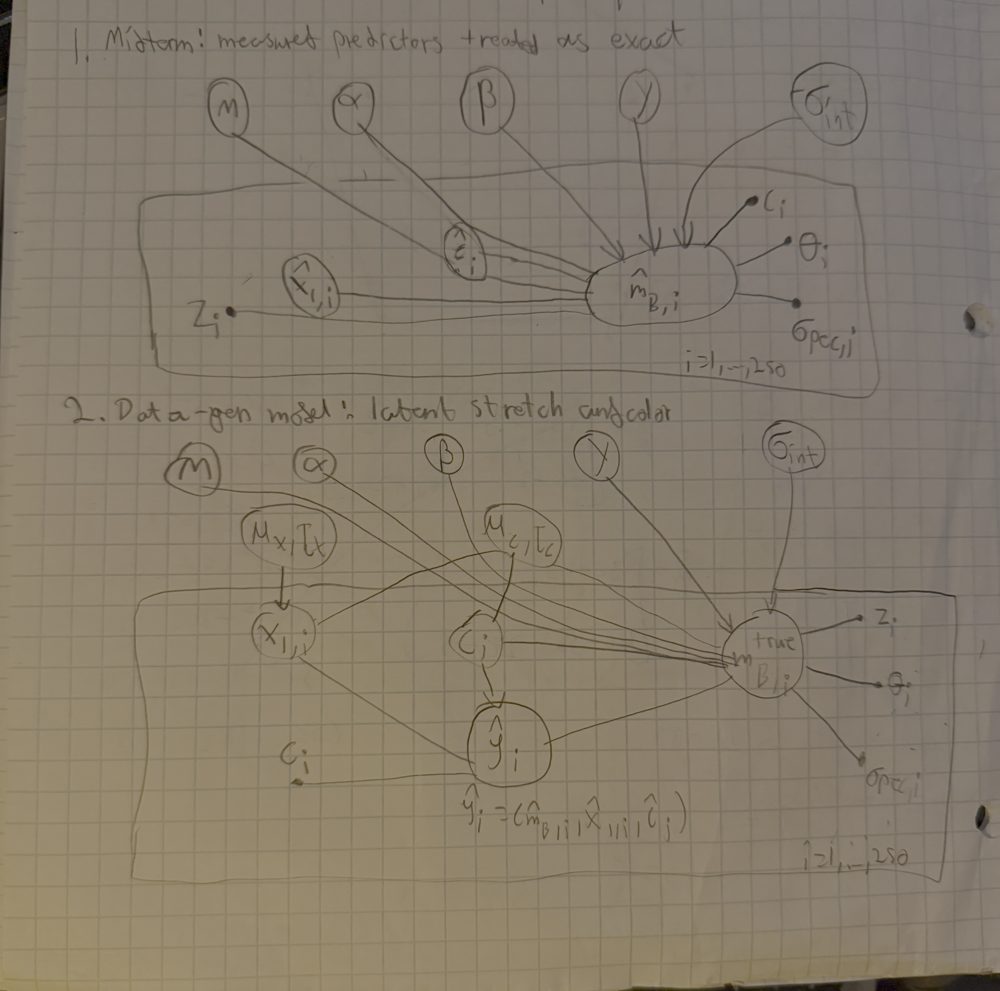

I simulated 30 datasets using a true $\beta=2.9$ mag/color and fitted each dataset with both the midterm and latent models. All 30 fits succeeded.

The midterm model significantly underestimates $\beta$ because it treats noisy measurements of x_1 and c as exact regressors. Including their measurement errors only in the residual variance does not correct this errors in variables bias, causing the fitted slopes to be attenuated toward zero. The latent model instead accounts for the underlying true values and their population distributions, recovering a \(\beta\) consistent with the true value.

The bias is larger for $\beta$ than for $\alpha$ because color has greater measurement uncertainty relative to its population spread. The error to population width ratio is 0.419 for color, compared with 0.159 for stretch. Therefore, measurement noise makes up a larger fraction of the observed color variation, leading to stronger attenuation in $\beta$.

As an additional check, the marginalized Gaussian fit on the real data gave $\beta=3.2132$, closely matching the PyMC posterior median of 3.2104.

## Part 2: What the survey didn't keep (30%)

We'll use a simplified model of photon-counting aperture photometry. A source with true flux $F$ (in units of a reference flux $F_0$) gives, on average, $\epsilon F + \nu$ counts - $\epsilon = 226.27$ counts per $F_0$ is the exposure, and $\nu = 9.373$ counts is the background (sky plus detector) that lands in the aperture with or without a source. The survey keeps a source only if it counts $n > 32$ photons (about a 4$\sigma$ detection) - anything fainter never makes it into the catalog.

The true fluxes come from a **lognormal** population, $\ln F \sim \mathcal{N}(\mu, \sigma)$. Your catalog, `08/data/<your netid>.csv`, has one column, `n_counts`, for the first 1500 sources the survey detected. I generated it, so I know your $\mu$ and $\sigma$, and how many sources the survey missed. Your $\mu$ and $\sigma$ are graded by how far they are from the truth in units of your own error bars.

1. Histogram your counts (a log axis in $n$ helps). The paragraph above is how the survey was designed to work - your file is what it actually did. If you find something the paragraph doesn't describe, you'll have to deal with it, and there is more than one legitimate way to account for it. Reread Day 19's slides on what a survey doesn't keep before you decide. Make a call, and defend it. Explain what you found and how many sources it affects, what you did about it and why you chose that over the alternatives, and what it does to $\mu$ and $\sigma$ (show it - fit with and without your fix). Carry your choice through every fit below.
2. Write the sampling distribution of $n$ given $F$. Write the detection probability $p_{\rm det}(F) = P(n > 32 \mid F)$ in closed form using `scipy.special.gammainc` (the regularized lower incomplete gamma function - **be careful** whether the threshold is 32 or 33), and check it against `scipy.stats.poisson.sf` at a few fluxes. Plot $p_{\rm det}$ against $F$ on a log axis. At what flux is a source detected half the time?
3. Draw the graph for this survey, with the detection step in it (the selection graph from class is the model). Which nodes are latent, which are data, which are fixed, and where do $N$ and $N_{\rm det}$ go?
4. For a source that 2.1 doesn't affect, the naive likelihood of its count, with its true flux integrated out, is
$$p(n_i \mid \mu, \sigma) = \int \mathrm{Poisson}(n_i \mid \epsilon F + \nu)\, \mathcal{N}(\ln F \mid \mu, \sigma)\, d\ln F.$$
Do that integral on a grid in $\ln F$, and find the $(\mu, \sigma)$ that maximizes the product over your 1500 sources. Then add the detector by subtracting $N_{\rm det} \ln f_{\rm det}(\mu, \sigma)$ from the log-likelihood, with $f_{\rm det} = \int p_{\rm det}(F)\, \mathcal{N}(\ln F \mid \mu, \sigma)\, d\ln F$ the fraction of the population that the survey detects, and fit again. Report $(\mu, \sigma)$ for both fits with uncertainties (curvature, a grid of the posterior, or `PyMC` with `pm.Potential` - your choice, but state which). What is $f_{\rm det}$, and so about how many sources did your survey miss?
5. Histogram $\ln \hat F$, with $\hat F = (n - \nu)/\epsilon$. On it, draw the naive population (scaled to your 1500 sources) and the corrected population (scaled to the $N_{\rm det}/f_{\rm det}$ sources it says were there). Then simulate your survey from the corrected fit - sample that many true fluxes, sample a Poisson count for each, put the counts through your detector as it actually ran (2.1), keep the ones with $n > 32$, and plot the histogram of their $\ln \hat F$ on the same axes. Does it match your data? Now also draw the corrected population times $p_{\rm det}(F)$, and compare it with your histogram at the faint end. The fit is right, so why don't they match? (We gave this a name in class.) Finally, which way did ignoring the detector bias $\mu$ and $\sigma$? Explain why it biases both of them.

#### Hints:
- Use a grid in $\ln F$ from about $-14$ to $8$, with spacing no coarser than 0.01, and check that your answer doesn't change when you halve it.
- Unlike the LIGO example in class, there is no $\ln p_{\rm det}$ term for each source. Detection depends on $n$, which you observed, and every source in your catalog has $n > 32$.

In [ ]:
# Part 2: your work here
n = pd.read_csv(LAB + f'{NETID}.csv')['n_counts'].to_numpy()
nu, eps, n_th = 9.373, 226.27, 32

In [ ]:
#2.1

n = pd.read_csv(LAB + f'{NETID}.csv')['n_counts'].to_numpy()
nu, eps, n_th = 9.373, 226.27, 32

bins = np.geomspace(max(1, n[n > 0].min()), n.max() + 1, 50)

plt.figure(figsize=(9, 5))
plt.hist(n[n > 0], bins=bins, alpha=0.75, edgecolor='black')
plt.axvline(n_th, color='red', linestyle='--',
            label=f'Detection threshold (n > {n_th})')

plt.xscale('log')
plt.xlabel('Photon counts (n)')
plt.ylabel('Number of sources')
plt.title('Distribution of Detected Photon Counts')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print(f"Total sources: {len(n)}")
print(f"Minimum count: {n.min()}")
print(f"Maximum count: {n.max()}")
print(f"Sources at or below threshold: {np.sum(n <= n_th)}")
print(f"Median count: {np.median(n):.1f}")

In [ ]:
#2.1 cont.

from scipy.special import logsumexp

n_cap = 1200
n_capped = np.sum(n == n_cap)

logF = np.arange(-14, 8.005, 0.005)
dlogF = logF[1] - logF[0]
lam = nu + eps * np.exp(logF)

counts, freq = np.unique(n, return_counts=True)

log_pmf = stats.poisson.logpmf(counts[:, None], lam[None, :])
log_det = stats.poisson.logsf(n_th, lam)
log_cap = stats.poisson.logsf(n_cap - 1, lam)

def nll(p, censored=True):
    mu, sigma = p

    log_prior = (
        -0.5*((logF - mu)/sigma)**2
        - np.log(sigma*np.sqrt(2*np.pi))
        + np.log(dlogF)
    )

    log_prob = logsumexp(log_pmf + log_prior, axis=1)

    if censored:
        log_prob[counts == n_cap] = logsumexp(log_cap + log_prior)

    log_pdet = logsumexp(log_det + log_prior)

    return -(np.sum(freq*log_prob) - len(n)*log_pdet)


start = [np.log((np.median(n) - nu)/eps), 1.0]
bounds = [(-7, 4), (0.05, 3)]

fit_naive = minimize(nll, start, args=(False,),
                     method='L-BFGS-B', bounds=bounds)

fit_fixed = minimize(nll, start, args=(True,),
                     method='L-BFGS-B', bounds=bounds)

if not (fit_naive.success and fit_fixed.success):
    print("Warning: check optimizer convergence.")

mu_naive, sigma_naive = fit_naive.x
mu_hat, sigma_hat = fit_fixed.x

print(f"Total detected sources: {len(n)}")
print(f"Sources at detection threshold or below: {np.sum(n <= n_th)}")
print(f"Sources at 1200 counts: {n_capped}")
print(f"Fraction affected: {n_capped/len(n):.2%}\n")

results = pd.DataFrame({
    'Fit': ['Ignoring saturation', 'Right-censored at 1200'],
    'mu': [mu_naive, mu_hat],
    'sigma': [sigma_naive, sigma_hat]
})

display(results.round(4))

print(f"Change in mu = {mu_hat - mu_naive:+.4f}")
print(f"Change in sigma = {sigma_hat - sigma_naive:+.4f}")

The histogram shows that there is an unusual pile up at  1,200 counts, suggesting an upper measurement limit or saturation that was not mentioned in the survey description. This affects 62 sources (4.13%).

I chose to treat these sources as right censored, meaning their actual counts could be 1,200 or greater. This preserves information about the bright sources without assuming their counts are exactly 1,200. An alternative would be to exclude these sources and account for the additional selection, but censoring retains more information.

I fitted the lognormal population both with and without the saturation correction, accounting for the lower detection threshold in both cases. Accounting for saturation decreases $\mu$ by 0.4181 and increases $\sigma$ by 0.2595. The larger $\sigma$ indicates a broader underlying flux distribution, since the saturated measurements could represent sources much brighter than 1,200 counts. The inferred $\mu$ decreases as the model adjusts to the broader distribution while matching the detected sources.

In [ ]:
# 2.2

from scipy.special import gammainc
from scipy.optimize import brentq

def p_det(F):
    lam = eps*F + nu
    return gammainc(n_th + 1, lam)

F_test = np.array([0.01, 0.05, 0.1, 0.2, 1.0])
p_gamma = p_det(F_test)
p_poisson = stats.poisson.sf(n_th, eps*F_test + nu)

print("Comparison of detection probabilities:")
for F, pg, pp in zip(F_test, p_gamma, p_poisson):
    print(f"F = {F:.2f}: gammainc = {pg:.6f}, poisson.sf = {pp:.6f}")

print(f"\nMaximum difference = {np.max(np.abs(p_gamma - p_poisson)):.2e}")

F_half = brentq(lambda F: p_det(F) - 0.5, 0, 10)

print(f"\n50% detection flux = {F_half:.5f} F0")
print(f"Detection probability = {p_det(F_half):.4f}")

F_grid = np.logspace(-3, 1, 500)

plt.figure(figsize=(8, 5))
plt.plot(F_grid, p_det(F_grid), label='Detection probability')
plt.axhline(0.5, color='gray', linestyle='--', label='50% detection')
plt.axvline(F_half, color='red', linestyle='--',
            label=f'F = {F_half:.3f} F0')

plt.xscale('log')
plt.xlabel(r'True flux $F$ ($F_0$)')
plt.ylabel(r'$P(n > 32 \mid F)$')
plt.title('Survey Detection Probability')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Photon counts follow a Poisson distribution with mean $\lambda=\epsilon F+\nu$:

$F\sim\mathrm{Poisson}(\epsilon F+\nu)$

Since the survey only detects sources with $n>32$, the detection probability is

$p_{\rm det}(F)=P(n>32\mid F)
=\operatorname{gammainc}(33,\epsilon F+\nu)$

The argument is 33 because the first detected count is 33. I verified this against `scipy.stats.poisson.sf(32, lambda)` at several fluxes, obtaining a maximum difference of zero within numerical precision. From the plot, the detection probability increases rapidly around $F\approx0.1F_0$. The flux at which a source is detected half the time is

$F_{50}=0.10295\,F_0$

This shows that detection is probabilistic rather than a sharp cutoff in true flux because photon counts fluctuate according to Poisson statistics.

2.3

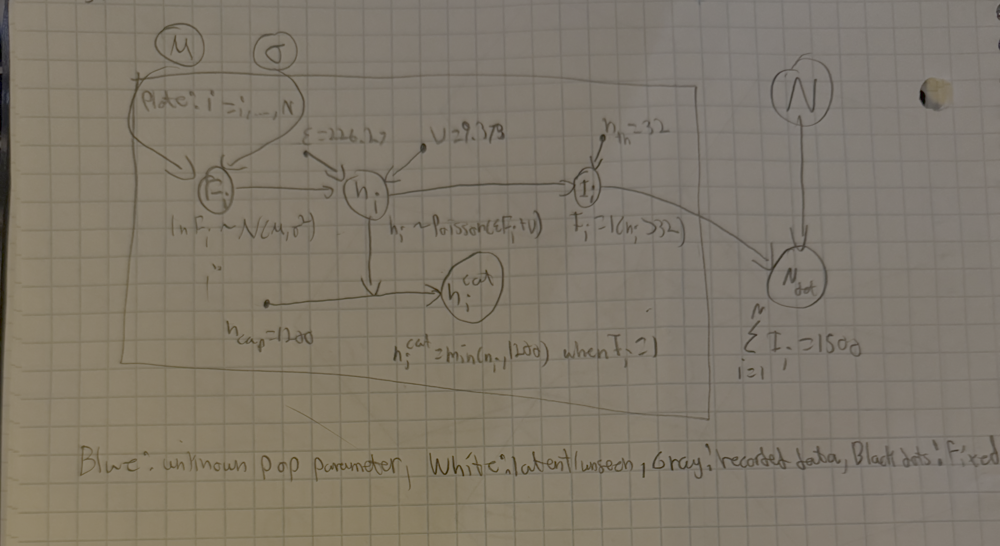

The population parameters $\mu$ and $\sigma$ determine the latent true flux $F_i$ for each source. The flux, exposure $\epsilon$, and background $\nu$ determine the photon count $n_i$ through a Poisson distribution. The detection flag $I_i$ is determined by whether $n_i>32$, so selection depends on the measured photon counts rather than directly on the true flux.

The plate runs over all N sources, including those never detected. N is the unknown total number of sources, while $N_{\rm det}=1500$ is the observed number detected, with $N_{\rm det}=\sum_i I_i$. Both are outside the plate.

I also included the inferred saturation limit at 1200 counts, so the catalog measurement is $n_i^{\rm cat}=\min(n_i,1200)$ for detected sources. This accounts for the right-censored measurements identified in part 2.1.

The missing sources are important because the detection probability depends on photon counts, which depend on the underlying flux distribution. Ignoring them would bias our inferred population parameters.

In [ ]:
# 2.4

from scipy.special import logsumexp

uncapped = counts < n_cap
n_censored = freq[~uncapped].sum()

def nll_selection(p, correct_detection=False):
    mu, sigma = p

    log_prior = stats.norm.logpdf(logF, mu, sigma) + np.log(dlogF)

    log_prob = logsumexp(log_pmf[uncapped] + log_prior, axis=1)
    log_like = np.sum(freq[uncapped] * log_prob)

    log_like += n_censored * logsumexp(log_cap + log_prior)

    if correct_detection:
        log_fdet = logsumexp(log_det + log_prior)
        log_like -= len(n) * log_fdet

    return -log_like


start = [mu_hat, sigma_hat]
bounds = [(-7, 4), (0.05, 3)]

fit_naive = minimize(
    nll_selection, start, args=(False,),
    method='L-BFGS-B', bounds=bounds
)

fit_selected = minimize(
    nll_selection, start, args=(True,),
    method='L-BFGS-B', bounds=bounds
)

def curvature_errors(fit, corrected):
    x = fit.x
    h = 0.003
    H = np.zeros((2, 2))
    f = lambda p: nll_selection(p, corrected)
    f0 = f(x)

    for i in range(2):
        e = np.eye(2)[i] * h
        H[i, i] = (f(x + e) - 2*f0 + f(x - e)) / h**2

    e1, e2 = np.eye(2) * h
    H[0, 1] = H[1, 0] = (
        f(x + e1 + e2) - f(x + e1 - e2)
        - f(x - e1 + e2) + f(x - e1 - e2)
    ) / (4*h**2)

    return np.sqrt(np.diag(np.linalg.inv(H)))


err_naive = curvature_errors(fit_naive, False)
err_selected = curvature_errors(fit_selected, True)

mu_naive, sigma_naive = fit_naive.x
mu_hat, sigma_hat = fit_selected.x

log_prior = stats.norm.logpdf(logF, mu_hat, sigma_hat) + np.log(dlogF)
f_det = np.exp(logsumexp(log_det + log_prior))

N_total = len(n) / f_det
N_missed = N_total - len(n)

print("Naive fit (without detection correction):")
print(f"mu = {mu_naive:.4f} ± {err_naive[0]:.4f}")
print(f"sigma = {sigma_naive:.4f} ± {err_naive[1]:.4f}")

print("\nDetection-corrected fit:")
print(f"mu = {mu_hat:.4f} ± {err_selected[0]:.4f}")
print(f"sigma = {sigma_hat:.4f} ± {err_selected[1]:.4f}")

print("\nSurvey completeness:")
print(f"Detection fraction = {f_det:.4f} ({100*f_det:.2f}%)")
print(f"Detected sources = {len(n)}")
print(f"Estimated total sources = {N_total:.0f}")
print(f"Estimated missed sources = {N_missed:.0f}")

print(f"\nOptimizer success: naive={fit_naive.success}, corrected={fit_selected.success}")

I compared a naive likelihood that ignores detection selection with a corrected likelihood that includes the normalization term $N_{\rm det}\ln f_{\rm det}$. Both fits account for the 62 right censored sources at 1200 counts. I estimated the $1\sigma$ uncertainties using the inverse Hessian of the negative log-likelihood.

The naive fit overestimates $\mu$ and underestimates $\sigma$ because the catalog preferentially contains brighter sources, while many faint sources are missing. Correcting for detection shifts the inferred population toward lower fluxes and increases its spread.

Using the corrected parameters, I obtained a detection fraction of 0.5392.


With 1500 detected sources, the estimated total population is

$N_{\rm total}\approx\frac{1500}{0.5393}\approx2782$

Therefore, the survey missed approximately

$N_{\rm missed}\approx1282\text{ sources}$

This means the survey detects only about 53.93% of the underlying population and misses approximately 46.07%.

In [ ]:
#2.5


grid_fits = {}

for h in [0.01, 0.005]:
    logF = np.arange(-14, 8 + h/2, h)
    dlogF = h
    lam = nu + eps*np.exp(logF)

    log_pmf = stats.poisson.logpmf(counts[:, None], lam[None, :])
    log_det = stats.poisson.logsf(n_th, lam)
    log_cap = stats.poisson.logsf(n_cap - 1, lam)

    fit_selected = minimize(
        nll_selection, fit_selected.x, args=(True,),
        method='L-BFGS-B', bounds=bounds
    )
    if not fit_selected.success:
        raise RuntimeError("Selection-corrected fit failed")

    grid_fits[h] = fit_selected.x.copy()

print("Grid convergence:")
for h, p in grid_fits.items():
    print(f"Step {h}: mu = {p[0]:.5f}, sigma = {p[1]:.5f}")

print("Change on halving grid:", grid_fits[0.005] - grid_fits[0.01])

fit_naive = minimize(
    nll_selection, fit_naive.x, args=(False,),
    method='L-BFGS-B', bounds=bounds
)

fit_no_cap = minimize(
    nll, fit_selected.x, args=(False,),
    method='L-BFGS-B', bounds=bounds
)

if not (fit_naive.success and fit_no_cap.success):
    raise RuntimeError("Comparison fit failed")

mu_naive, sigma_naive = fit_naive.x
mu_hat, sigma_hat = fit_selected.x

log_prior = stats.norm.logpdf(logF, mu_hat, sigma_hat) + np.log(dlogF)
f_det = np.exp(logsumexp(log_det + log_prior))
N_total = len(n) / f_det

rng = np.random.default_rng(457)

lnF_true = rng.normal(mu_hat, sigma_hat, size=round(N_total))
n_true = rng.poisson(eps*np.exp(lnF_true) + nu)

n_sim = np.minimum(n_true, n_cap)
n_sim = n_sim[n_sim > n_th]

lnF_obs = np.log((n - nu)/eps)
lnF_sim = np.log((n_sim - nu)/eps)

bins = np.linspace(-3.5, np.log((n_cap-nu)/eps) + 0.08, 55)
x = np.linspace(bins[0], bins[-1], 500)
width = bins[1] - bins[0]

pop_naive = len(n)*stats.norm.pdf(x, mu_naive, sigma_naive)*width
pop_corrected = N_total*stats.norm.pdf(x, mu_hat, sigma_hat)*width
pop_detected = pop_corrected*p_det(np.exp(x))

plt.figure(figsize=(10, 6))

plt.hist(lnF_obs, bins=bins, alpha=0.4, label='Observed catalog')
plt.hist(lnF_sim, bins=bins, histtype='step', linewidth=2,
         label='Simulated detected catalog')

plt.plot(x, pop_naive, label='Naive population (1500 sources)')
plt.plot(x, pop_corrected, label='Corrected population (all sources)')
plt.plot(x, pop_detected, linestyle='--',
         label=r'Corrected population $\times\,p_{\rm det}(F)$')

plt.axvline(np.log((n_th+1-nu)/eps), color='gray',
            linestyle=':', label='Minimum measurable detected flux')

plt.xlabel(r'$\ln \hat F$ for catalogs; $\ln F$ for population curves')
plt.ylabel('Number of sources per bin')
plt.title('Observed, Simulated, and Underlying Flux Distributions')
plt.legend(fontsize=9)
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

print(f"Observed detected sources = {len(n)}")
print(f"Simulated detected sources = {len(n_sim)}")
print(f"Estimated total population = {N_total:.0f}")
print(f"Detection fraction = {f_det:.4f}")

print("\nIgnoring saturation vs corrected (both selection-adjusted):")
print(f"Without saturation correction: {fit_no_cap.x}")
print(f"With saturation correction:    {fit_selected.x}")
print(f"Bias in mu = {fit_no_cap.x[0] - mu_hat:+.4f}")
print(f"Bias in sigma = {fit_no_cap.x[1] - sigma_hat:+.4f}")

**ANSWER (the two fits, f_det and the number missed, then the explanation):**

The simulation produced 1,505 detected sources which is very close to the actual 1,500. The simulated histogram also matches the overall shape of the observed distribution, including the pile up at the saturation limit.

The corrected population multiplied by $p_{\rm det}(F)$ does not perfectly match the observed histogram at the faint end because it describes the distribution of true fluxes among detected sources, while the histogram uses noisy flux estimates $\hat F=(n-\nu)/\epsilon$. Poisson fluctuations allow intrinsically faint sources to scatter above the detection threshold, making their measured fluxes appear brighter. This is Eddington bias.

Ignoring the detection selection biased $\mu$ upward, from -2.1039 to -0.7386, and $\sigma$ downward, from 1.8668 to 1.1250. This happens because faint sources are preferentially missing, shifting the observed distribution toward brighter fluxes and reducing its apparent spread.

Ignoring saturation while still correcting for detection also biased $\mu$ upward by 0.4184 and $\sigma$ downward by 0.2595. Capping bright sources at 1,200 counts hides the high flux tail, making the inferred population narrower.

Finally, halving the integration grid spacing from 0.01 to 0.005 changed $\mu$ and $\sigma$ by less than $2 \times 10^{-5}$, showing convergence.

## Part 3: A supernova in two dimensions (25%)

This one is real. The Carnegie Supernova Project (CSP-I) observed nearby Type Ia supernovae in six optical bands, from $u$ (364 nm) to $i$ (761 nm). Look up your supernova and your held-out band in `08/data/csp_assignments.csv`. Your light curve is `08/data/csp/<SN>.csv`, with columns `mjd`, `band`, `wavelength_A` (the band's effective wavelength), `flux_ujy` and `flux_err_ujy` (flux density in μJy), and the magnitudes they came from. The header gives the redshift and the date of maximum light in $B$. Data: Krisciunas et al. 2017, AJ 154, 211 (CC BY 4.0; credit the Carnegie Supernova Project).

Work in rest-frame phase, $(\mathrm{MJD} - T_{B\,\rm max})/(1+z)$, from $-10$ to $+40$ days, and divide every flux by the peak $B$ flux. Note that `V0`, `V1` and `V` are three versions of the same filter (within 32 Å) - treat them as one band, $V$.

A supernova's light curves in neighboring bands look alike, so a Gaussian process in **two** inputs, phase and wavelength, can learn all six at once and predict a band it never saw.

1. Plot every band against phase.
2. Fit a GP to the flux as a function of (phase, wavelength) using every band **except** your held-out one, with wavelength in microns (so both inputs are numbers of order 1-50). Use a kernel with its own length scale in phase and in wavelength (an anisotropic squared-exponential) times a fitted amplitude, each point's own measurement error, and a small white-noise term that you also fit. Fit the hyperparameters by maximizing the marginal likelihood (as in Lab 07), from more than one start. `sklearn`'s `GaussianProcessRegressor` (with `alpha` set to the squared errors, `normalize_y=False`, and `ConstantKernel` times `RBF` plus `WhiteKernel`) or your own Cholesky code from Lab 07 are both fine. Report the two length scales, and comment on what each means physically for a supernova.
3. Predict your held-out band at its epochs, with the GP's $1\sigma$ band, and plot it over the data. Report the rms residual as a fraction of the peak, and the fraction of held-out points within $1\sigma$ (add the GP's variance and the measurement variance). Does the GP's error bar look reasonable?
4. Now hold out $u$ instead, and report the same two numbers. Why is this so much harder? Think particularly about what the kernel assumes, and how far $u$ is from the other bands compared with your first held-out band.

In [ ]:
# Part 3: your work here
asg = pd.read_csv(LAB + 'csp_assignments.csv')
SN, HOLD = asg.loc[asg.netid == NETID, ['sn', 'holdout_band']].iloc[0]
path = LAB + f'csp/{SN}.csv'
hdr = [l for l in open(path) if l.startswith('#')]          # the header lines: source, license, redshift, date of B maximum
z = float([l for l in hdr if 'z_helio' in l][0].split(':')[-1])
tmax = float([l for l in hdr if 'B-max MJD' in l][0].split(':')[1].split('+/-')[0])
d = pd.read_csv(path, comment='#')
d['band'] = d['band'].replace({'V0': 'V', 'V1': 'V'})   # V0, V1 and V are the same filter - treat them as one band
print(f'{SN}: z = {z}, B maximum at MJD {tmax}, {len(d)} points; held-out band: {HOLD}')

In [ ]:
#3.1

d['phase'] = (d['mjd'] - tmax) / (1 + z)
d['wave_um'] = d.groupby('band')['wavelength_A'].transform('median') / 1e4

peak_B = d.loc[d.band == 'B', 'flux_ujy'].max()

d = d[(d.phase >= -10) & (d.phase <= 40)].copy()
d['flux'] = d['flux_ujy'] / peak_B
d['err'] = d['flux_err_ujy'] / peak_B

plt.figure(figsize=(9, 5))

for band, group in d.groupby('band'):
    plt.errorbar(group.phase, group.flux, yerr=group.err,
                 fmt='o', ms=4, capsize=2, label=band)

plt.xlabel('Rest-frame phase (days)')
plt.ylabel('Flux / peak B flux')
plt.title(f'{SN}: Multi-band Light Curves')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print(f"Peak B flux = {peak_B:.2f} μJy")
print(f"Points in phase range: {len(d)}")
print(f"Bands: {sorted(d.band.unique())}")

I converted the observation times to rest frame phase and normalized the fluxes by the peak B band flux of 747.50 μJy. After restricting the data to −10 to +40 days, I had 88 observations across six bands.

The light curves have similar overall shapes, with brightness increasing toward maximum light and declining afterward. However, the peak brightness and decline rate vary between bands. The u band is fainter and declines more rapidly than the other bands, especially after maximum light.

In [ ]:
#3.2 

from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import ConstantKernel, RBF, WhiteKernel

def fit_gp(held):
    train = d[d.band != held]

    X = train[['phase', 'wave_um']].to_numpy()
    y = train.flux.to_numpy()
    err = train.err.to_numpy()

    kernel = (
        ConstantKernel(1.0, (1e-3, 100))
        * RBF([10, 0.1], length_scale_bounds=[(0.5, 100), (0.01, 2)])
        + WhiteKernel(1e-3, (1e-7, 0.1))
    )

    gp = GaussianProcessRegressor(
        kernel=kernel,
        alpha=err**2,
        normalize_y=False,
        n_restarts_optimizer=4,
        random_state=457
    )

    gp.fit(X, y)
    return gp


gp = fit_gp(HOLD)

lengths = gp.kernel_.k1.k2.length_scale

print(f"Held-out band: {HOLD}")
print(f"Phase length scale = {lengths[0]:.3f} days")
print(f"Wavelength length scale = {lengths[1]:.4f} μm")
print(f"Fitted kernel: {gp.kernel_}")

I fitted a 2D GP using all bands except V, with separate length scales for phase and wavelength. I used an anisotropic squared-exponential kernel with a fitted amplitude and white noise term, including each measurement's uncertainty. The hyperparameters were optimized from multiple starting points.

The fitted phase length scale is 9.799 days, indicating that the supernova brightness varies smoothly over timescales of roughly 10 days. The wavelength length scale is 0.1099 μm, indicating that nearby optical wavelengths have correlated light curves, with the correlation weakening as their wavelength separation increases.

In [ ]:
#3.3
test = d[d.band == HOLD].sort_values('phase')
X_test = test[['phase', 'wave_um']].to_numpy()

pred, std = gp.predict(X_test, return_std=True)

rms = np.sqrt(np.mean((test.flux.to_numpy() - pred)**2))
sigma_total = np.sqrt(std**2 + test.err.to_numpy()**2)
coverage = np.mean(np.abs(test.flux.to_numpy() - pred) <= sigma_total)

phase_grid = np.linspace(-10, 40, 300)
wave = test.wave_um.median()
X_grid = np.column_stack([phase_grid, np.full(len(phase_grid), wave)])

mean_grid, std_grid = gp.predict(X_grid, return_std=True)

plt.figure(figsize=(9, 5))
plt.errorbar(test.phase, test.flux, yerr=test.err,
             fmt='o', capsize=2, label=f'Observed {HOLD}')
plt.plot(phase_grid, mean_grid, label='GP prediction')
plt.fill_between(phase_grid, mean_grid-std_grid,
                 mean_grid+std_grid, alpha=0.25, label='GP 1σ')

plt.xlabel('Rest-frame phase (days)')
plt.ylabel('Flux / peak B flux')
plt.title(f'{SN}: Held-out {HOLD} Prediction')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print(f"Held-out points: {len(test)}")
print(f"RMS residual = {rms:.4f} of peak B flux")
print(f"Within 1σ = {coverage:.1%}")

The GP predicts the held out V band light curve well, with an RMS residual of 0.0234. Of the 15 held out observations, 80.0% fall within 1σ when combining the GP predictive variance and measurement variance.

The predicted curve closely follows the observed rise, peak, and decline of the V band flux. Although the coverage is slightly higher than the expected 68%, this is reasonable for a sample of only 15 points. Overall, the GP uncertainty appears reasonably calibrated, possibly slightly conservative.

In [ ]:
#3.4
gp_u = fit_gp('u')

test_u = d[d.band == 'u'].sort_values('phase')
X_u = test_u[['phase', 'wave_um']].to_numpy()

pred_u, std_u = gp_u.predict(X_u, return_std=True)

rms_u = np.sqrt(np.mean((test_u.flux.to_numpy() - pred_u)**2))
sigma_u = np.sqrt(std_u**2 + test_u.err.to_numpy()**2)
coverage_u = np.mean(np.abs(test_u.flux.to_numpy() - pred_u) <= sigma_u)

phase_grid = np.linspace(-10, 40, 300)
X_grid_u = np.column_stack([
    phase_grid, np.full(len(phase_grid), test_u.wave_um.median())
])

mean_u, band_u = gp_u.predict(X_grid_u, return_std=True)

plt.figure(figsize=(9, 5))
plt.errorbar(test_u.phase, test_u.flux, yerr=test_u.err,
             fmt='o', capsize=2, label='Observed u')
plt.plot(phase_grid, mean_u, label='GP prediction')
plt.fill_between(phase_grid, mean_u-band_u,
                 mean_u+band_u, alpha=0.25, label='GP 1σ')

plt.xlabel('Rest-frame phase (days)')
plt.ylabel('Flux / peak B flux')
plt.title(f'{SN}: Held-out u Prediction')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print(f"u-band points: {len(test_u)}")
print(f"u RMS residual = {rms_u:.4f} of peak B flux")
print(f"u within 1σ = {coverage_u:.1%}")

print(f"\nV RMS = {rms:.4f}, u RMS = {rms_u:.4f}")
print(f"V coverage = {coverage:.1%}, u coverage = {coverage_u:.1%}")

**ANSWER (length scales, the two held-out tests, then why u is harder):**


When holding out u instead, the RMS residual increases to 0.1258 , and only 15.4% of the observations fall within 1σ. This is much worse than the V band prediction, indicating that the GP substantially underestimates its prediction errors for u.

The u band is harder to predict because it lies at the shortest wavelength edge of the observed bands, requiring extrapolation rather than interpolation. The squared-exponential kernel assumes smooth correlations across wavelength, but the u band light curve declines much faster than those of the neighboring optical bands. So the GP overpredicts the u band flux after maximum brightness and produces uncertainty intervals that are too narrow to capture the difference.

## Part 4: AI-use appendix and verification plan (10%)

1. **AI use**: which tools, for what, what they got wrong, and how you caught it. "I didn't use any" is fine if true.
2. **Reflection**: what would have gone wrong in your answer if you had not checked the AI's output? Name the specific thing.
3. **Verification plan**: the checks you ran before trusting your Part 1 and Part 2 numbers, and what failure would have looked like for each. Part 1.3 is already one. For Part 2, one check to consider is to simulate a catalog yourself with a $\mu$ and $\sigma$ you choose, through the same detector, run both fits on it, and see whether the corrected fit gets back what you put in and the naive one doesn't. One catalog isn't enough - comment on how many you'd need.

**AI-USE APPENDIX:**

I used ChatGPT

- Helping write print statements, plotting code, and formatting results.

- Helping create functions for likelihood calculations and numerical optimization.

- Helping implement the hierarchical PyMC model with latent stretch and color variables.

- Helping implement the numerical integration over the lognormal flux distribution.

- Helping write the survey simulation and verification tests.

- Helping implement the detection and saturation corrections.

Checking my results and helping identify anything that needed further testing or explanation.


The initial numerical integration code used a grid spacing of approximately 0.016, which was larger than the assignment's required maximum of 0.01. I noticed this when reviewing the hints and corrected it to 0.005.


**REFLECTION:**

Without checking the AI's output, I would have used a numerical integration grid that did not meet the assignment's requirements. Although the convergence test showed that the final parameters were similar, I would not have verified that the numerical integration was sufficiently accurate.

Another important issue was distinguishing between measurement uncertainty and the underlying population distribution. In Part 1, just including measurement errors in the residual variance was not enough to correct attenuation bias in $\beta$. In Part 2, ignoring the detection threshold or treating saturated counts as exact measurements would have biased the inferred flux population. Without checking these assumptions through simulations, I could have accepted fitted values and small error bars that looked reasonable but were systematically biased. A model can converge successfully and still give incorrect results if the likelihood does not properly represent how the data were generated.

**VERIFICATION PLAN:**

I simulated 30 catalogs with known $\mu=-2.10$ and $\sigma=1.85$, applying the same Poisson noise, detection threshold, and saturation limit as the real survey. I then fitted each catalog using both the naive and corrected models.

Failure: The corrected model would fail if either parameter differed from the truth by more than 3$/sigma$, showed bias comparable to the naive model, or had frequent optimization failures.

All 30 fits succeeded. The corrected model recovered $\mu$ and $\sigma$ within 0.63 and 0.34 standard errors of the truth, respectively, while the naive model showed substantial bias in both parameters.

Thirty simulations are good for an initial check, but I would use at least 100–200 to assess bias and uncertainty coverage more reliably.

In [ ]:
#Check
rng = np.random.default_rng(45708)
n_sim = 30
mu_true, sigma_true = -2.10, 1.85

pmf_grid = stats.poisson.pmf(
    np.arange(n_th + 1, n_cap)[:, None], lam[None, :]
)
det_grid = stats.poisson.sf(n_th, lam)
cap_grid = stats.poisson.sf(n_cap - 1, lam)

w_true = stats.norm.pdf(logF, mu_true, sigma_true) * dlogF
fdet_true = det_grid @ w_true

def simulation_nll(p, k, freq, corrected):
    mu, sigma = p
    w = stats.norm.pdf(logF, mu, sigma) * dlogF
    probs = pmf_grid @ w

    unc = k < n_cap
    ll = np.sum(freq[unc] * np.log(
        np.maximum(probs[k[unc] - n_th - 1], 1e-300)
    ))
    ll += freq[~unc].sum() * np.log(max(cap_grid @ w, 1e-300))

    if corrected:
        ll -= np.sum(freq) * np.log(max(det_grid @ w, 1e-300))

    return -ll

naive_estimates = []
corrected_estimates = []
failed = 0

for i in range(n_sim):
    detected = np.array([], dtype=int)

    while len(detected) < len(n):
        F = rng.lognormal(mu_true, sigma_true,
                          size=int(1.2 * len(n) / fdet_true))
        raw = rng.poisson(eps * F + nu)
        detected = np.r_[detected,
                         np.minimum(raw[raw > n_th], n_cap)]

    fake = detected[:len(n)]
    k, freq = np.unique(fake, return_counts=True)

    fit_n = minimize(simulation_nll, fit_naive.x,
                     args=(k, freq, False),
                     method='L-BFGS-B', bounds=bounds)

    fit_c = minimize(simulation_nll, fit_selected.x,
                     args=(k, freq, True),
                     method='L-BFGS-B', bounds=bounds)

    if fit_n.success and fit_c.success:
        naive_estimates.append(fit_n.x)
        corrected_estimates.append(fit_c.x)
    else:
        failed += 1

naive_estimates = np.array(naive_estimates).reshape(-1, 2)
corrected_estimates = np.array(corrected_estimates).reshape(-1, 2)

n_valid = len(corrected_estimates)
if n_valid < 2:
    raise RuntimeError("Too few successful fits")

print(f"Successful simulations: {n_valid}/{n_sim}")
print(f"True mu = {mu_true:.4f}, true sigma = {sigma_true:.4f}\n")

for name, estimates in [('Naive', naive_estimates),
                        ('Corrected', corrected_estimates)]:
    means = estimates.mean(axis=0)
    errors = estimates.std(axis=0, ddof=1) / np.sqrt(n_valid)

    print(f"{name} fit:")
    print(f"  mu = {means[0]:.4f} ± {errors[0]:.4f}")
    print(f"  sigma = {means[1]:.4f} ± {errors[1]:.4f}")
    print(f"  Deviations from truth = "
          f"{(means[0]-mu_true)/errors[0]:+.2f}, "
          f"{(means[1]-sigma_true)/errors[1]:+.2f} SE\n")

corrected_mean = corrected_estimates.mean(axis=0)
corrected_se = corrected_estimates.std(axis=0, ddof=1) / np.sqrt(n_valid)
z_scores = np.abs(
    (corrected_mean - [mu_true, sigma_true]) / corrected_se
)

print("Corrected recovery:",
      "PASS" if np.all(z_scores < 3) else "FAIL")
print(f"Failed paired fits: {failed}")